# Loudness, pitch, spectrograms and harmony

This notebook shows pitch or harmony related features of `acids_dataset` : loudness (LUFS), fundamental frequency, mel and
constant-Q spectrograms, chroma, harmonicity and inharmonicity.

In [1]:
import math
import torch
import matplotlib.pyplot as plt
from acids_dataset import features as F

SR = 22050
t = torch.arange(3 * SR) / SR

def harmonic(f0, n=10, amp=0.3, stretch=0.):
    """harmonic tone ; f0 may be a tensor (time-varying) ; stretch > 0 gives inharmonic partials k * sqrt(1 + stretch k^2)."""
    f0 = torch.as_tensor(f0, dtype=torch.float32).expand(t.shape) if not torch.is_tensor(f0) or f0.ndim == 0 else f0
    phase = 2 * math.pi * torch.cumsum(f0, 0) / SR
    return sum(amp / k * torch.sin(k * math.sqrt(1 + stretch * k ** 2) * phase) for k in range(1, n + 1))[None]

## Loudness

`Loudness` is the integrated loudness (ITU-R BS.1770, in LUFS), per chunk or per frame with `frame_length`. Silence is
floored to `min_loudness` (-70 LUFS) instead of `-inf`, such that it can be used in losses. With
`keep_channels=True` (default), loudness is given per channel.

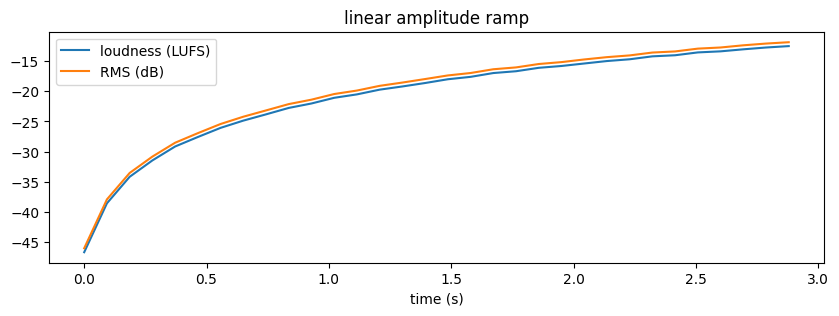

shape per channel : torch.Size([2, 32])
silence           : tensor([-70.])


In [2]:
crescendo = harmonic(220.) * torch.linspace(0.001, 1, len(t))
loudness = F.Loudness(frame_length=2048, keep_channels=False, sr=SR)(crescendo)
rms = F.RMS(frame_length=2048, sr=SR)(crescendo)

fig, ax = plt.subplots(figsize=(10, 3))
frames = torch.arange(loudness.shape[-1]) * 2048 / SR
ax.plot(frames, loudness.flatten(), label="loudness (LUFS)")
ax.plot(torch.arange(len(rms)) * 2048 / SR, rms, label="RMS (dB)")
ax.set_xlabel("time (s)"); ax.legend(); ax.set_title("linear amplitude ramp"); plt.show()

print("shape per channel :", F.Loudness(frame_length=2048, sr=SR)(torch.cat([crescendo, 0.5 * crescendo])).shape)
print("silence           :", F.Loudness(sr=SR)(torch.zeros(1, SR)))

## Fundamental frequency

`F0` estimates the fundamental frequency with `yin` and `pyin` (librosa), and optionally with `crepe`, `pesto`
or `world` if installed. `Pitch` has the same estimators, with outputs in midi. Here, a vibrato around A3 followed by
a glissando :

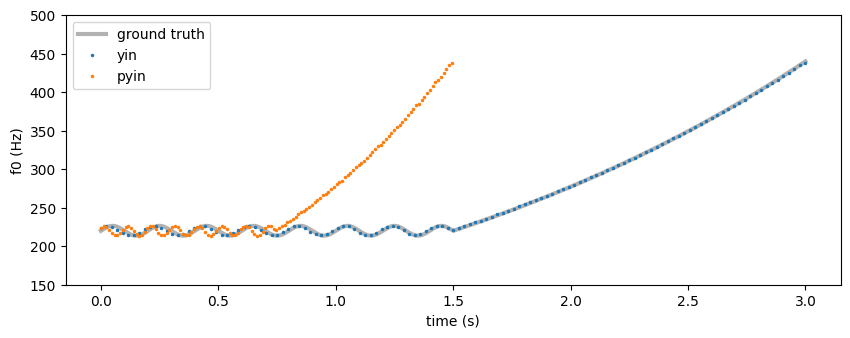

available estimators : ['yin', 'pyin', 'pesto']


In [3]:
vibrato = 220 * 2 ** (0.5 / 12 * torch.sin(2 * math.pi * 5 * t))
glissando = 220 * 2 ** (torch.clamp(t - 1.5, min=0) / 1.5)
f0_true = torch.where(t < 1.5, vibrato, glissando)
melody = harmonic(f0_true, n=6)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t, f0_true, "k", lw=3, alpha=0.3, label="ground truth")
for mode in ["yin", "pyin"]:
    f0 = F.F0(mode=mode, sr=SR)(melody).flatten()
    times = torch.linspace(0, t[-1], len(f0))
    ax.plot(times, f0, ".", ms=3, label=mode)
ax.set_xlabel("time (s)"); ax.set_ylabel("f0 (Hz)"); ax.set_ylim(150, 500); ax.legend(); plt.show()

print("available estimators :", F.F0._valid_modes_)

## Mel and constant-Q spectrograms

`Mel` and `CQT` (librosa, with real and imaginary parts stacked on the channel axis) give time-frequency representations, that can be stored in pre-processed datasets or computed on the
fly (on whole batches, on GPU, see the dataset notebook).

mel : (1, 128, 331) | cqt : (2, 84, 130)


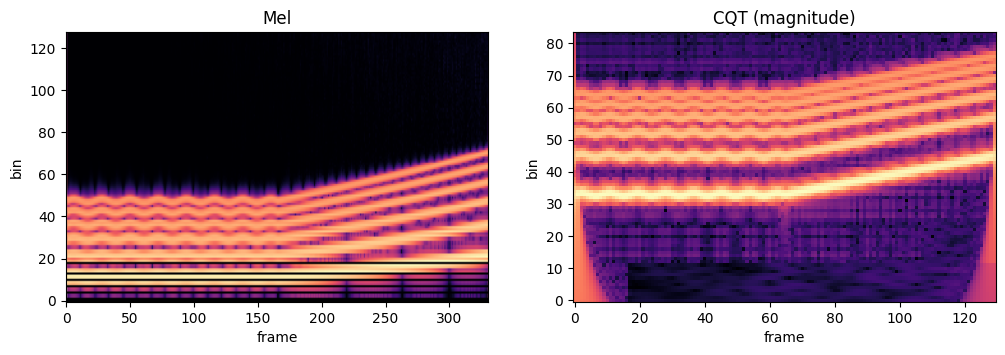

In [4]:
mel = torch.as_tensor(F.Mel(sr=SR)(melody))          # (channels, n_mels, n_frames)
cqt = torch.as_tensor(F.CQT(sr=SR)(melody))          # (2 * channels, n_bins, n_frames) : real and imaginary parts
print("mel :", tuple(mel.shape), "| cqt :", tuple(cqt.shape))
cqt_magnitude = torch.sqrt(cqt[0] ** 2 + cqt[1] ** 2)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, (name, spec) in zip(axes, [("Mel", mel[0]), ("CQT (magnitude)", cqt_magnitude)]):
    ax.imshow(torch.log(spec + 1e-5), origin="lower", aspect="auto", cmap="magma")
    ax.set_title(name); ax.set_xlabel("frame"); ax.set_ylabel("bin")
plt.show()

## Chroma

`Chroma` gives the energy of the 12 pitch classes per frame (0 : C, ..., 11 : B). A I - IV - V - I progression in C :

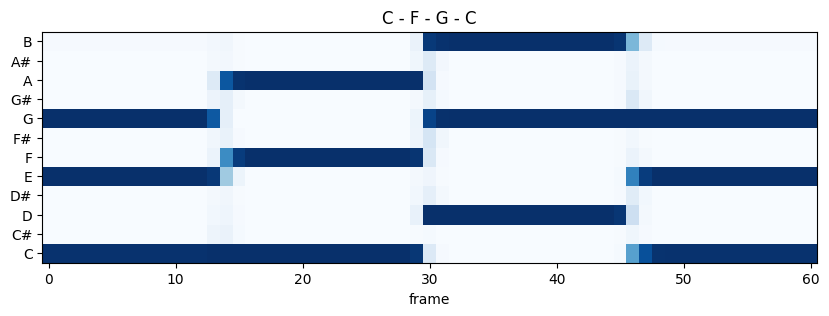

In [5]:
names = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
def chord(midis, duration=0.75):
    tt = torch.arange(int(duration * SR)) / SR
    return sum(0.2 * torch.sin(2 * math.pi * 440 * 2 ** ((m - 69) / 12) * tt) for m in midis) * torch.exp(-2 * tt)

progression = torch.cat([chord(c) for c in [[60, 64, 67], [65, 69, 72], [67, 71, 74], [60, 64, 67]]])[None]
chroma = F.Chroma(sr=SR)(progression)

fig, ax = plt.subplots(figsize=(10, 3))
ax.imshow(chroma, origin="lower", aspect="auto", cmap="Blues")
ax.set_yticks(range(12)); ax.set_yticklabels(names); ax.set_xlabel("frame"); ax.set_title("C - F - G - C"); plt.show()

## Harmonicity and inharmonicity

`Harmonicity` measures periodicity (normalized autocorrelation, in [0, 1]), and `Inharmonicity` the mean relative
deviation of partials from a harmonic series. Stretched partials (as in piano strings) increase inharmonicity while
keeping a high periodicity, whereas noise lowers harmonicity :

In [6]:
cases = {"harmonic": harmonic(220.), "stretched 0.001": harmonic(220., stretch=0.001),
         "stretched 0.005": harmonic(220., stretch=0.005), "noisy": harmonic(220.) + 0.3 * torch.randn(1, len(t)),
         "noise": 0.3 * torch.randn(1, len(t))}
for name, x in cases.items():
    print("%-16s harmonicity %.2f | inharmonicity %.4f" % (name, F.Harmonicity(sr=SR)(x).mean(), F.Inharmonicity(sr=SR)(x).mean()))

harmonic         harmonicity 1.00 | inharmonicity 0.0001
stretched 0.001  harmonicity 0.97 | inharmonicity 0.0061
stretched 0.005  harmonicity 0.91 | inharmonicity 0.0166
noisy            harmonicity 0.45 | inharmonicity 0.0008
noise            harmonicity 0.07 | inharmonicity 0.0260
